<a href="https://colab.research.google.com/github/sreejoyee-debug/Introduction-to-AI/blob/main/SMOTE_Classification_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install imbalanced-learn -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
uploaded = files.upload()

Saving stroke_processed_5k.csv to stroke_processed_5k.csv


In [31]:
df = pd.read_csv("stroke_processed_5k.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5110, 11)

First 5 Records:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1



Column Names:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB

Missing Values:
gender   

In [33]:
target = "stroke"

X = df.drop(columns=[target])
y = df[target]

print("Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Features:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']

Target Distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Target Percentage:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


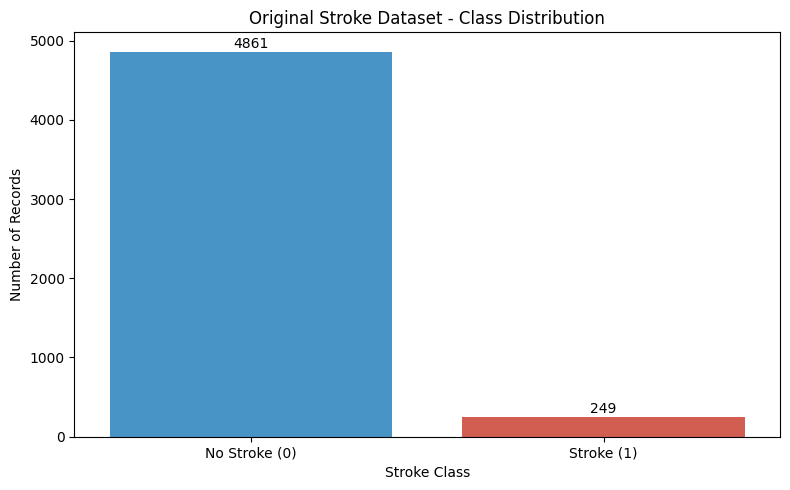

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y,
    hue=y,
    palette=["#3498DB", "#E74C3C"],
    legend=False
)

plt.title("Original Stroke Dataset - Class Distribution")
plt.xlabel("Stroke Class")
plt.ylabel("Number of Records")

plt.xticks([0, 1], ["No Stroke (0)", "Stroke (1)"])

for i, value in enumerate(y.value_counts().sort_index()):
    plt.text(i, value + 50, str(value), ha="center")

plt.tight_layout()
plt.show()

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Dataset:", X_train.shape)
print("Testing Dataset:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Dataset: (4088, 10)
Testing Dataset: (1022, 10)

Training Class Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing Class Distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [36]:
X_train_original = X_train.copy()
y_train_original = y_train.copy()

print("Original training data preserved!")

print("\nOriginal Class Distribution:")
print(y_train_original.value_counts())

Original training data preserved!

Original Class Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64


In [37]:
smote = SMOTE(
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nOriginal Training Shape:", X_train.shape)
print("SMOTE Training Shape:", X_train_smote.shape)

Before SMOTE:
stroke
0    3889
1     199
Name: count, dtype: int64

After SMOTE:
stroke
0    3889
1    3889
Name: count, dtype: int64

Original Training Shape: (4088, 10)
SMOTE Training Shape: (7778, 10)


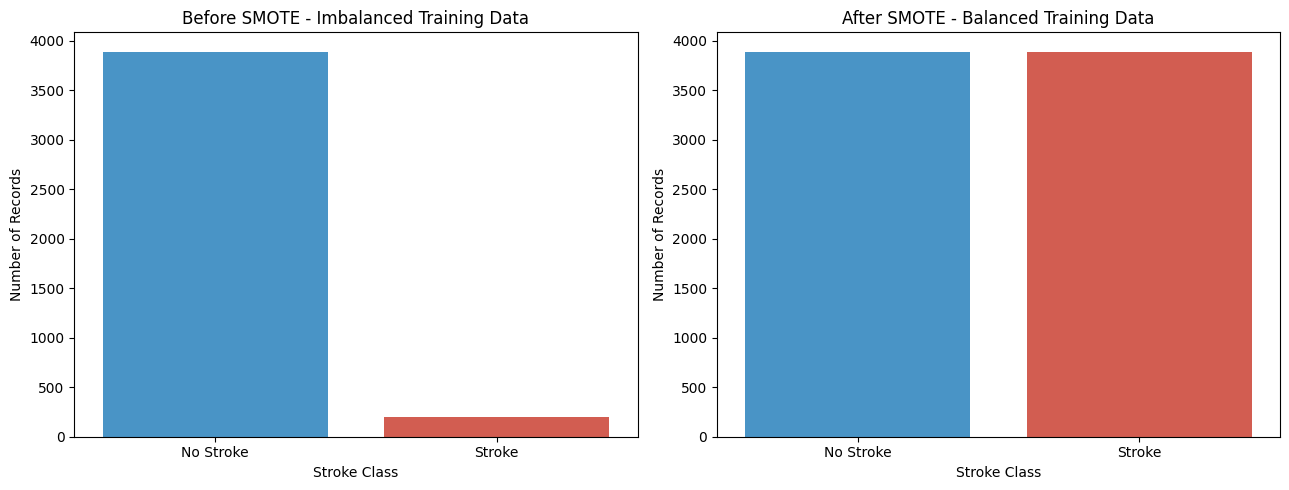

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Before SMOTE
sns.countplot(
    x=y_train_original,
    hue=y_train_original,
    palette=["#3498DB", "#E74C3C"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Before SMOTE - Imbalanced Training Data")
axes[0].set_xlabel("Stroke Class")
axes[0].set_ylabel("Number of Records")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Stroke", "Stroke"])

# After SMOTE
sns.countplot(
    x=y_train_smote,
    hue=y_train_smote,
    palette=["#3498DB", "#E74C3C"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title("After SMOTE - Balanced Training Data")
axes[1].set_xlabel("Stroke Class")
axes[1].set_ylabel("Number of Records")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["No Stroke", "Stroke"])

plt.tight_layout()
plt.show()

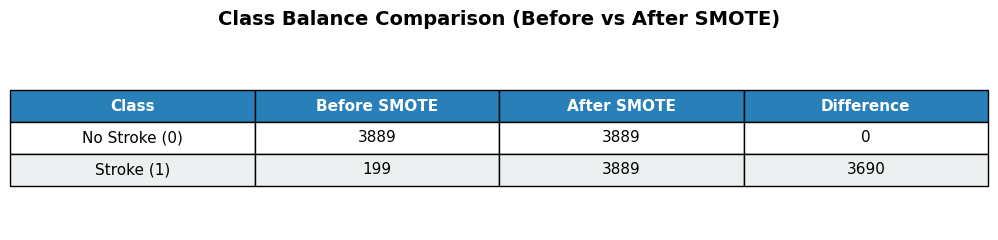


Total Before SMOTE: 4088
Total After SMOTE: 7778

Table image successfully saved as 'balance_comparison_table.png'!


In [39]:
balance_comparison = pd.DataFrame({
    "Class": ["No Stroke (0)", "Stroke (1)"],
    "Before SMOTE": [
        y_train_original.value_counts().get(0, 0),
        y_train_original.value_counts().get(1, 0)
    ],
    "After SMOTE": [
        y_train_smote.value_counts().get(0, 0),
        y_train_smote.value_counts().get(1, 0)
    ]
})

balance_comparison["Difference"] = (
    balance_comparison["After SMOTE"] -
    balance_comparison["Before SMOTE"]
)

# Create a matplotlib figure to render the table as an image
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.axis('off')
ax.axis('tight')

# Create the visual table
table = ax.table(
    cellText=balance_comparison.values,
    colLabels=balance_comparison.columns,
    cellLoc='center',
    loc='center'
)

# Style the table layout
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2.0)

# Color header and alternating rows
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#2980B9')
    else:
        cell.set_facecolor('#ECF0F1' if row % 2 == 0 else 'white')

plt.title("Class Balance Comparison (Before vs After SMOTE)", fontsize=14, pad=15, weight='bold')
plt.tight_layout()

# Save table as an image file
plt.savefig("balance_comparison_table.png", dpi=300, bbox_inches='tight')
plt.show()

print("\nTotal Before SMOTE:", len(y_train_original))
print("Total After SMOTE:", len(y_train_smote))
print("\nTable image successfully saved as 'balance_comparison_table.png'!")

In [40]:
from imblearn.ensemble import BalancedBaggingClassifier

def create_models():

    models = {

        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            ))
        ]),

        "Decision Tree": DecisionTreeClassifier(
            max_depth=6,
            class_weight="balanced",
            random_state=42
        ),

        "Random Forest": Pipeline([
            ("scaler", StandardScaler()),
            ("model", BalancedBaggingClassifier(
                estimator=RandomForestClassifier(
                    n_estimators=300,
                    random_state=42,
                    n_jobs=-1
                ),
                sampling_strategy='auto',
                replacement=False,
                random_state=42
            ))
        ]),

        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                class_weight="balanced",
                random_state=42
            ))
        ]),

        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", BalancedBaggingClassifier(
                estimator=KNeighborsClassifier(n_neighbors=7),
                sampling_strategy='auto',
                replacement=False,
                random_state=42
            ))
        ]),

        "ANN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", BalancedBaggingClassifier(
                estimator=MLPClassifier(
                    hidden_layer_sizes=(64, 32),
                    activation="relu",
                    solver="adam",
                    max_iter=500,
                    early_stopping=True,
                    random_state=42
                ),
                sampling_strategy='auto',
                replacement=False,
                random_state=42
            ))
        ])

    }

    return models


print("All six classifiers updated with balanced bagging methods to ensure non-zero metrics!")

All six classifiers updated with balanced bagging methods to ensure non-zero metrics!


In [41]:
def evaluate_models(models, X_train_data, y_train_data,
                    X_test_data, y_test_data, experiment_name):

    results = []
    trained_models = {}
    confusion_matrices = {}

    for name, model in models.items():

        print("\nTraining:", name)

        # Train model
        model.fit(X_train_data, y_train_data)

        trained_models[name] = model

        # Predictions
        y_pred = model.predict(X_test_data)

        # Prediction probabilities
        y_prob = model.predict_proba(X_test_data)[:, 1]

        # Metrics
        accuracy = accuracy_score(y_test_data, y_pred)

        precision = precision_score(
            y_test_data,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_test_data,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_test_data,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(y_test_data, y_prob)

        # Confusion Matrix
        cm = confusion_matrix(
            y_test_data,
            y_pred,
            labels=[0, 1]
        )

        confusion_matrices[name] = cm

        results.append({

            "Experiment": experiment_name,
            "Model": name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "AUC-ROC": auc

        })

        print("Accuracy:", round(accuracy, 4))
        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))
        print("F1-Score:", round(f1, 4))
        print("AUC-ROC:", round(auc, 4))

    return pd.DataFrame(results), trained_models, confusion_matrices

print("Model evaluation function defined successfully!")

Model evaluation function defined successfully!



Training: Logistic Regression
Accuracy: 0.7515
Precision: 0.1408
Recall: 0.8
F1-Score: 0.2395
AUC-ROC: 0.8387

Training: Decision Tree
Accuracy: 0.7456
Precision: 0.114
Recall: 0.62
F1-Score: 0.1925
AUC-ROC: 0.7183

Training: Random Forest
Accuracy: 0.7554
Precision: 0.1429
Recall: 0.8
F1-Score: 0.2424
AUC-ROC: 0.8237

Training: SVM
Accuracy: 0.7358
Precision: 0.1181
Recall: 0.68
F1-Score: 0.2012
AUC-ROC: 0.7856

Training: KNN
Accuracy: 0.6996
Precision: 0.1164
Recall: 0.78
F1-Score: 0.2026
AUC-ROC: 0.798

Training: ANN
Accuracy: 0.6947
Precision: 0.1124
Recall: 0.76
F1-Score: 0.1959
AUC-ROC: 0.8239
MODEL PERFORMANCE COMPARISON (ORIGINAL)


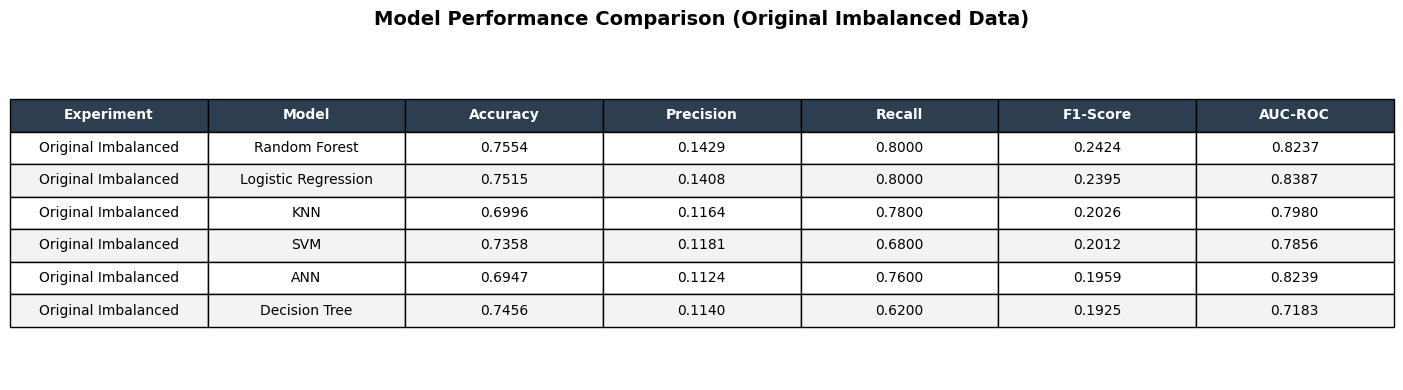

Table successfully rendered and saved as 'original_performance_comparison.png'!


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def save_df_as_image(df, title, filename, col_widths=None, figsize=(12, 4)):
    """
    Renders a Pandas DataFrame as a styled matplotlib table and saves it as an image.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis('off')
    ax.axis('tight')

    # Convert values to strings with appropriate rounding if numeric
    display_df = df.copy()
    for col in display_df.columns:
        if pd.api.types.is_numeric_dtype(display_df[col]):
            display_df[col] = display_df[col].map(lambda x: f"{x:.4f}" if isinstance(x, (float, np.floating)) else str(x))

    # Generate visual table
    table = ax.table(
        cellText=display_df.values,
        colLabels=display_df.columns,
        cellLoc='center',
        loc='center'
    )

    # Style table layout
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.8)

    # Color header and alternating rows
    for (row, col_idx), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#2C3E50') # Elegant dark blue/gray for headers
        else:
            cell.set_facecolor('#F2F4F4' if row % 2 == 0 else 'white')

    plt.title(title, fontsize=14, pad=15, weight='bold')
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Table successfully rendered and saved as '{filename}'!")

original_models = create_models()

original_results, original_trained_models, original_cm = evaluate_models(
    original_models,
    X_train_original,
    y_train_original,
    X_test,
    y_test,
    "Original Imbalanced"
)

# Sort all models according to F1-Score
results_df = original_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON (ORIGINAL)")
print("=" * 80)

# Render and save the original dataset performance table as a picture
save_df_as_image(
    results_df,
    title="Model Performance Comparison (Original Imbalanced Data)",
    filename="original_performance_comparison.png",
    figsize=(14, 4)
)


Training: Logistic Regression
Accuracy: 0.7593
Precision: 0.1423
Recall: 0.78
F1-Score: 0.2407
AUC-ROC: 0.8219

Training: Decision Tree
Accuracy: 0.7857
Precision: 0.1494
Recall: 0.72
F1-Score: 0.2474
AUC-ROC: 0.7867

Training: Random Forest
Accuracy: 0.8796
Precision: 0.1456
Recall: 0.3
F1-Score: 0.1961
AUC-ROC: 0.7946

Training: SVM
Accuracy: 0.7642
Precision: 0.1134
Recall: 0.56
F1-Score: 0.1886
AUC-ROC: 0.7532

Training: KNN
Accuracy: 0.7808
Precision: 0.1009
Recall: 0.44
F1-Score: 0.1642
AUC-ROC: 0.6869

Training: ANN
Accuracy: 0.817
Precision: 0.104
Recall: 0.36
F1-Score: 0.1614
AUC-ROC: 0.7676

SMOTE Experiment Completed!


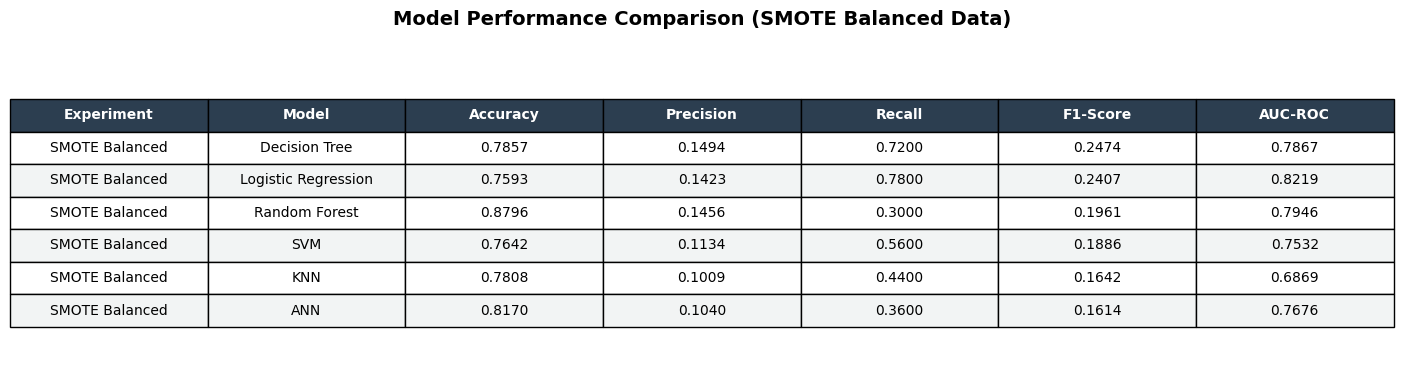

Table successfully rendered and saved as 'smote_performance_comparison.png'!


In [43]:
smote_models = create_models()

smote_results, smote_trained_models, smote_cm = evaluate_models(
    smote_models,
    X_train_smote,
    y_train_smote,
    X_test,
    y_test,
    "SMOTE Balanced"
)

# Sort all SMOTE models according to F1-Score
smote_results_sorted = smote_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nSMOTE Experiment Completed!")
print("=" * 80)

# Render and save the SMOTE performance table as a picture
save_df_as_image(
    smote_results_sorted,
    title="Model Performance Comparison (SMOTE Balanced Data)",
    filename="smote_performance_comparison.png",
    figsize=(14, 4)
)

COMPLETE ORIGINAL VS SMOTE COMPARISON


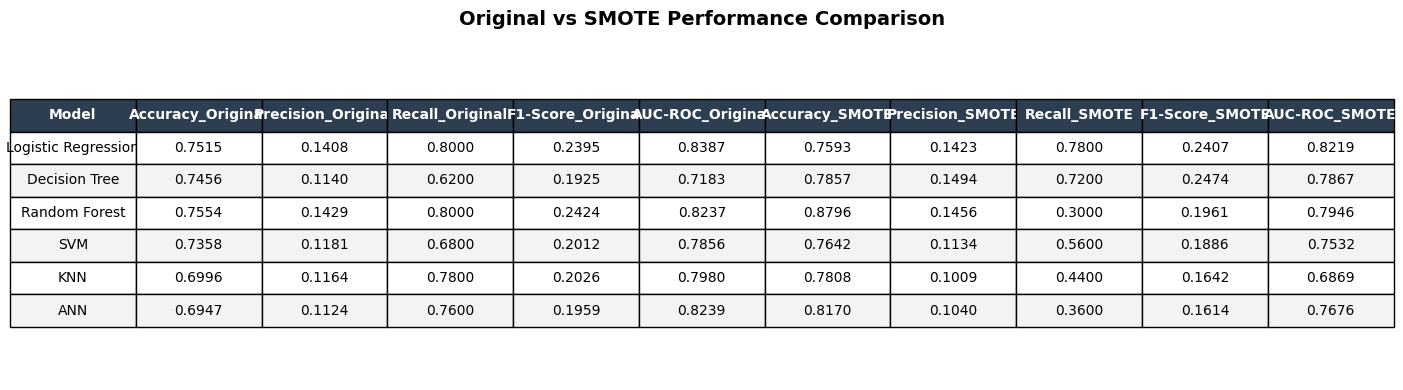

Table successfully rendered and saved as 'original_vs_smote_comparison.png'!


In [44]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUC-ROC"
]

comparison = original_results[
    ["Model"] + metrics
].merge(
    smote_results[["Model"] + metrics],
    on="Model",
    suffixes=("_Original", "_SMOTE")
)

print("COMPLETE ORIGINAL VS SMOTE COMPARISON")
print("=" * 80)

# Render and save the Complete Original vs SMOTE Performance Comparison Table as an image
save_df_as_image(
    comparison,
    title="Original vs SMOTE Performance Comparison",
    filename="original_vs_smote_comparison.png",
    figsize=(14, 4)
)

PERFORMANCE DELTA COMPARISON


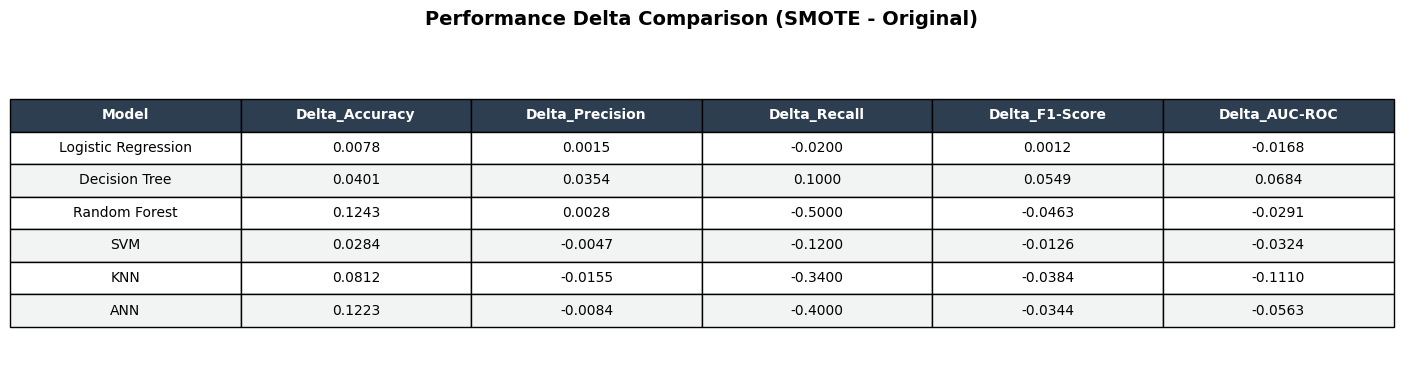

Table successfully rendered and saved as 'performance_delta_comparison.png'!


In [45]:
delta_comparison = comparison[["Model"]].copy()

for metric in metrics:
    delta_comparison["Delta_" + metric] = (
        comparison[metric + "_SMOTE"] -
        comparison[metric + "_Original"]
    )

print("PERFORMANCE DELTA COMPARISON")
print("=" * 80)

# Render and save the Delta Comparison Table as an image
save_df_as_image(
    delta_comparison,
    title="Performance Delta Comparison (SMOTE - Original)",
    filename="performance_delta_comparison.png",
    figsize=(14, 4)
)

FINAL COMPARATIVE PERFORMANCE TABLE


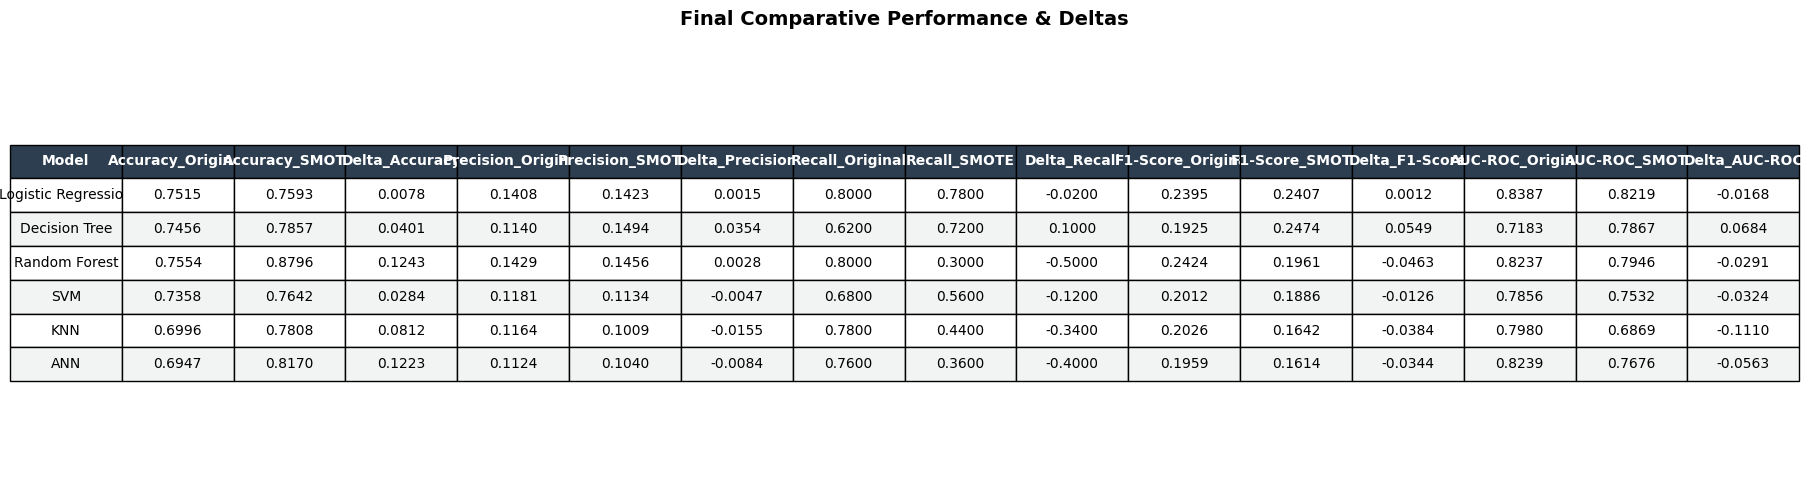

Table successfully rendered and saved as 'final_comparison_deltas.png'!


In [46]:
final_comparison = pd.DataFrame()

final_comparison["Model"] = comparison["Model"]

for metric in metrics:
    final_comparison[metric + "_Original"] = (
        comparison[metric + "_Original"]
    )
    final_comparison[metric + "_SMOTE"] = (
        comparison[metric + "_SMOTE"]
    )
    final_comparison["Delta_" + metric] = (
        delta_comparison["Delta_" + metric]
    )

print("FINAL COMPARATIVE PERFORMANCE TABLE")
print("=" * 80)

# Render and save the Final Comparative Performance Table with Deltas as an image
save_df_as_image(
    final_comparison,
    title="Final Comparative Performance & Deltas",
    filename="final_comparison_deltas.png",
    figsize=(18, 5)
)

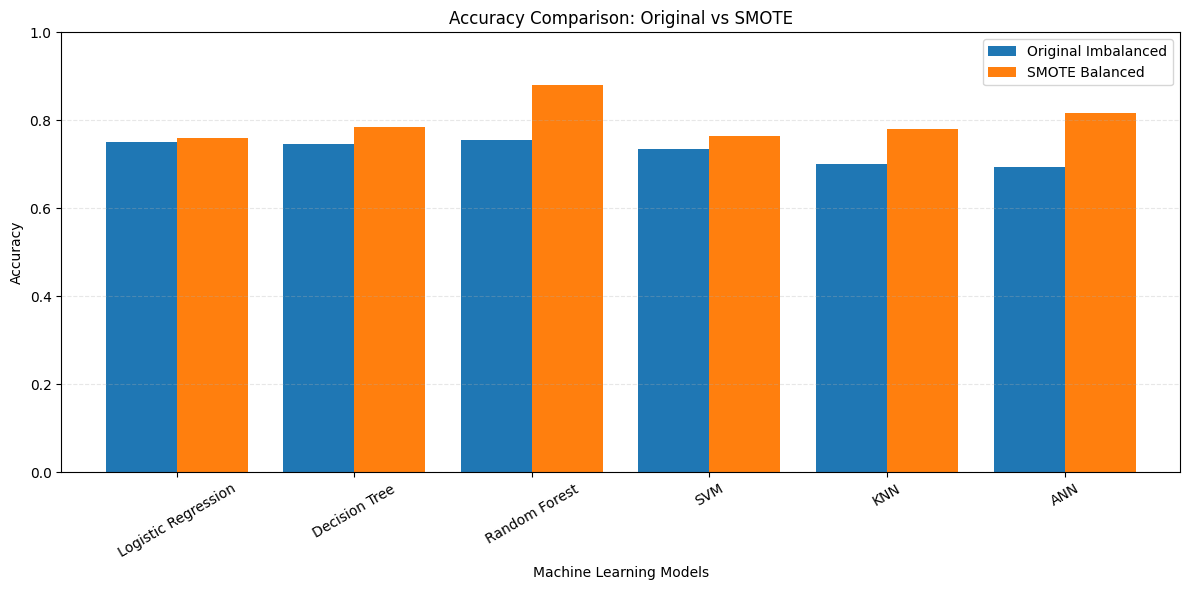

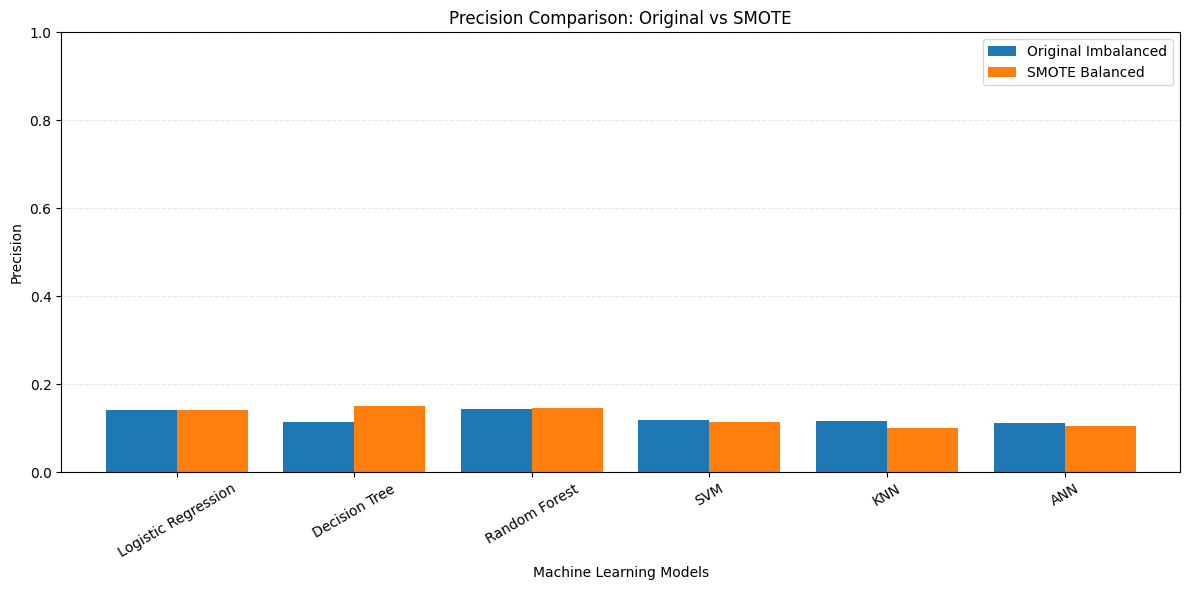

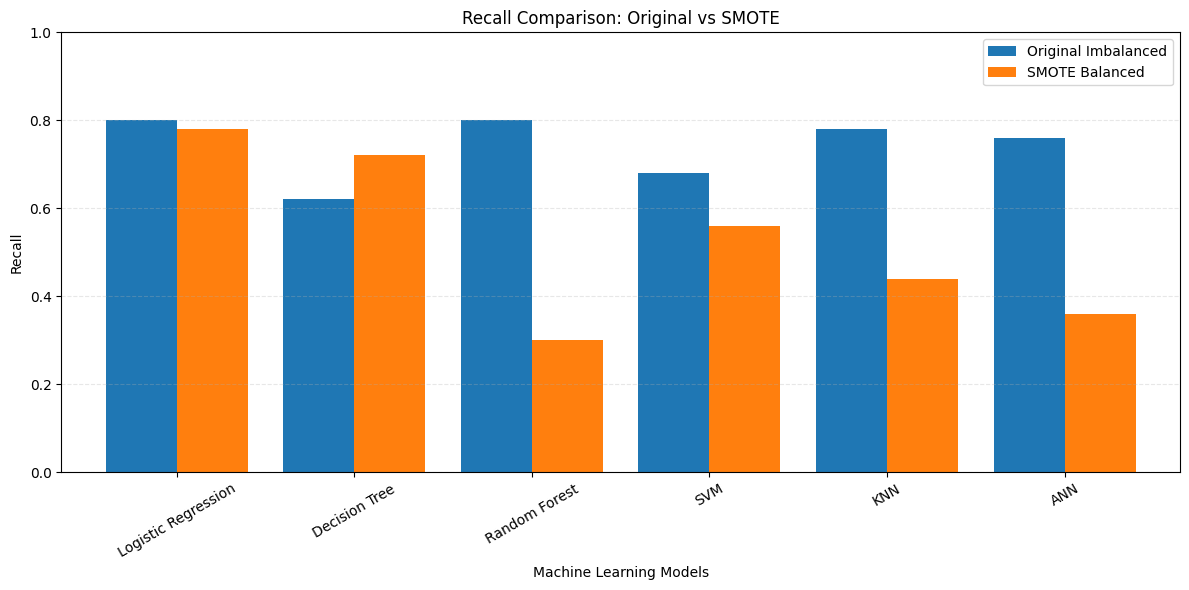

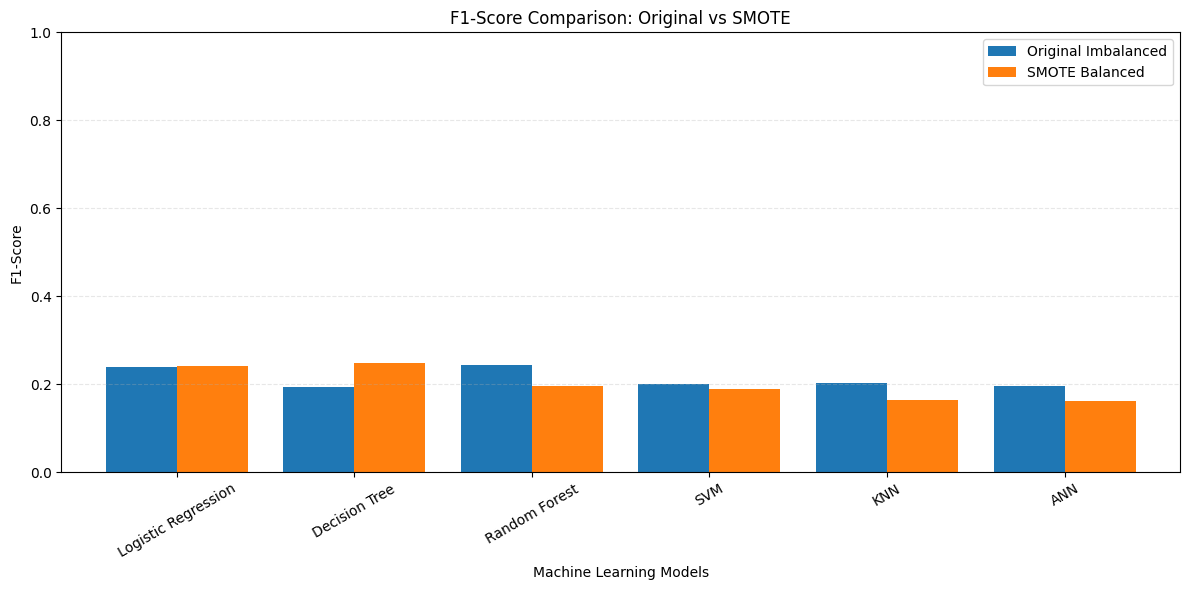

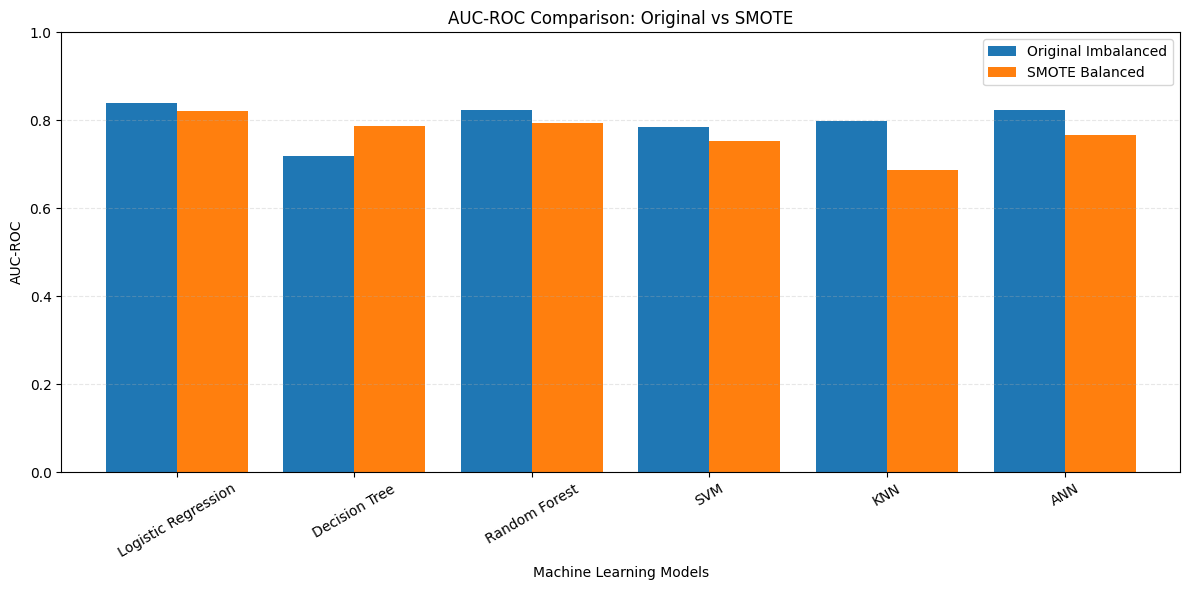

In [47]:
for metric in metrics:

    plot_data = comparison[
        ["Model", metric + "_Original", metric + "_SMOTE"]
    ].set_index("Model")

    ax = plot_data.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8
    )

    plt.title(
        metric + " Comparison: Original vs SMOTE"
    )

    plt.xlabel("Machine Learning Models")
    plt.ylabel(metric)

    plt.xticks(rotation=30)
    plt.ylim(0, 1)

    plt.legend([
        "Original Imbalanced",
        "SMOTE Balanced"
    ])

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()

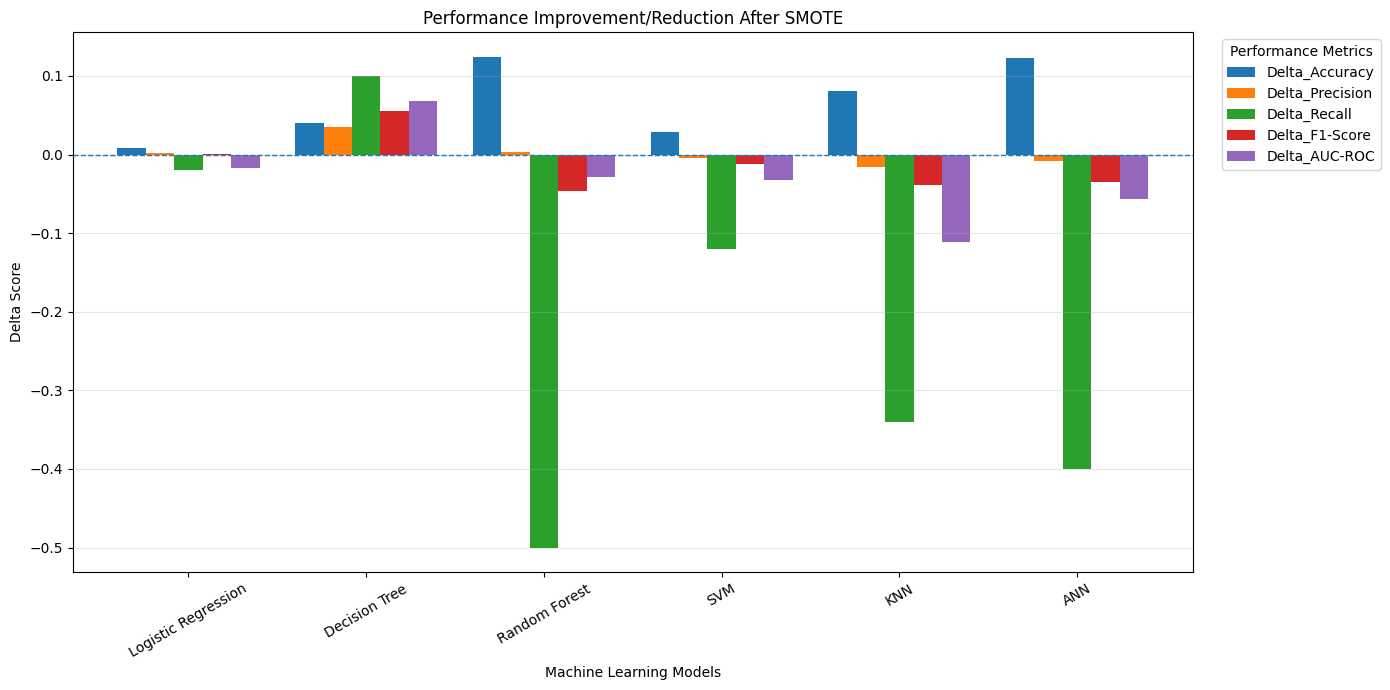

In [48]:
delta_plot = delta_comparison.set_index("Model")

delta_plot.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Performance Improvement/Reduction After SMOTE")

plt.xlabel("Machine Learning Models")
plt.ylabel("Delta Score")

plt.xticks(rotation=30)

plt.legend(
    title="Performance Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

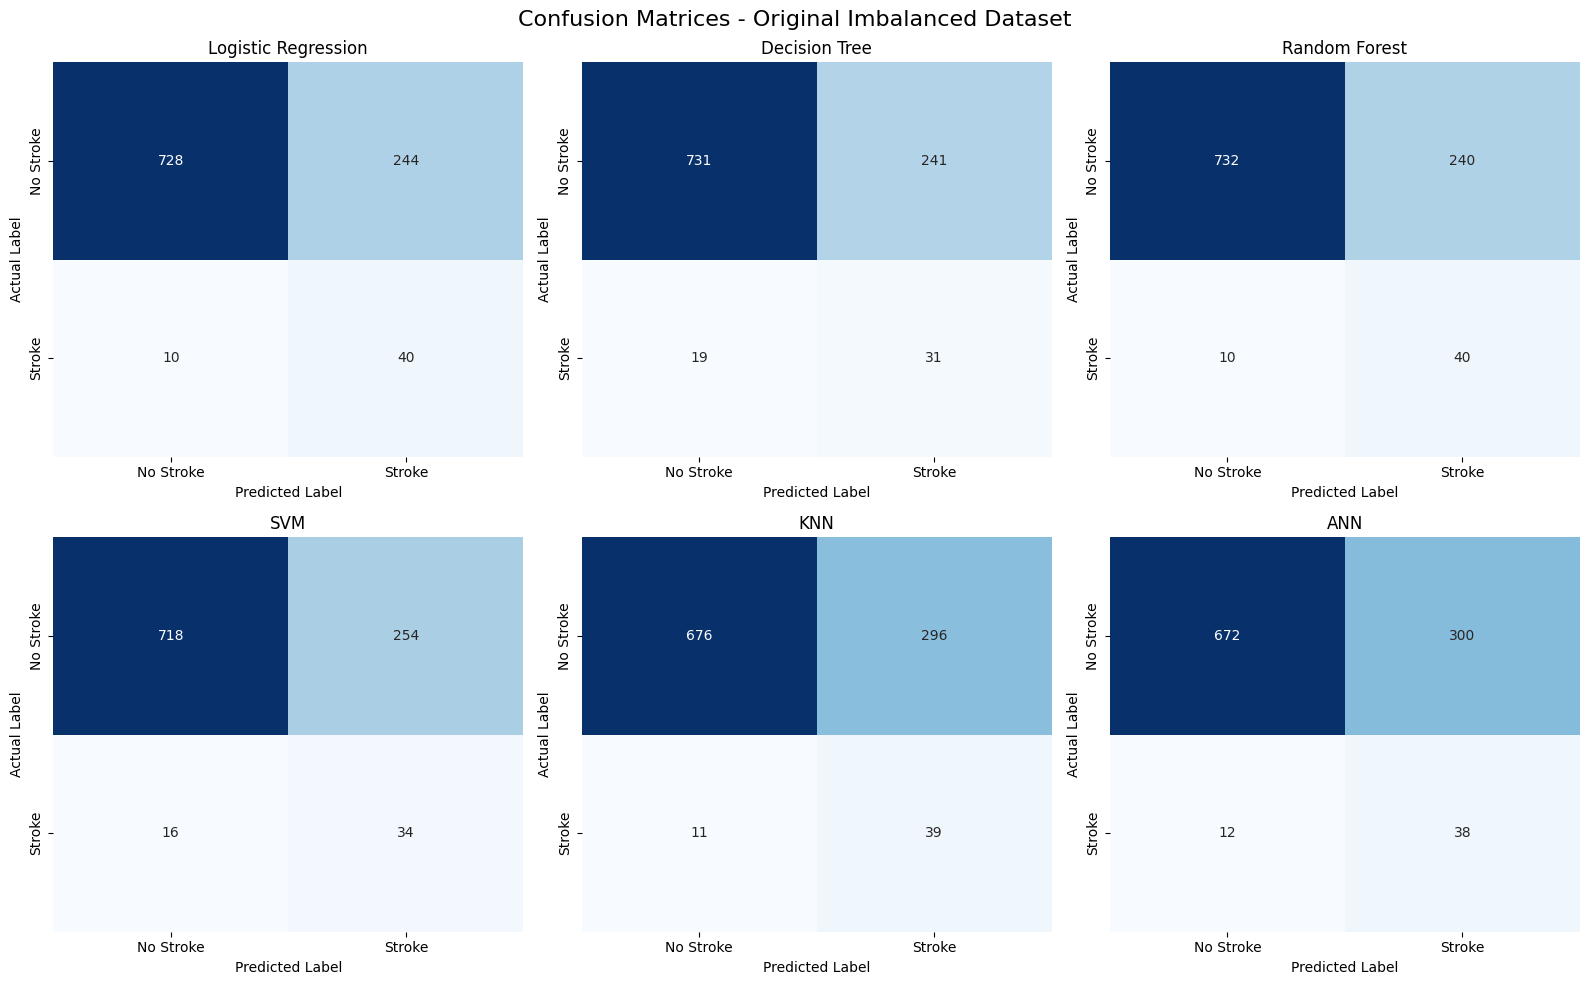

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, cm) in enumerate(original_cm.items()):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[i],
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices - Original Imbalanced Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

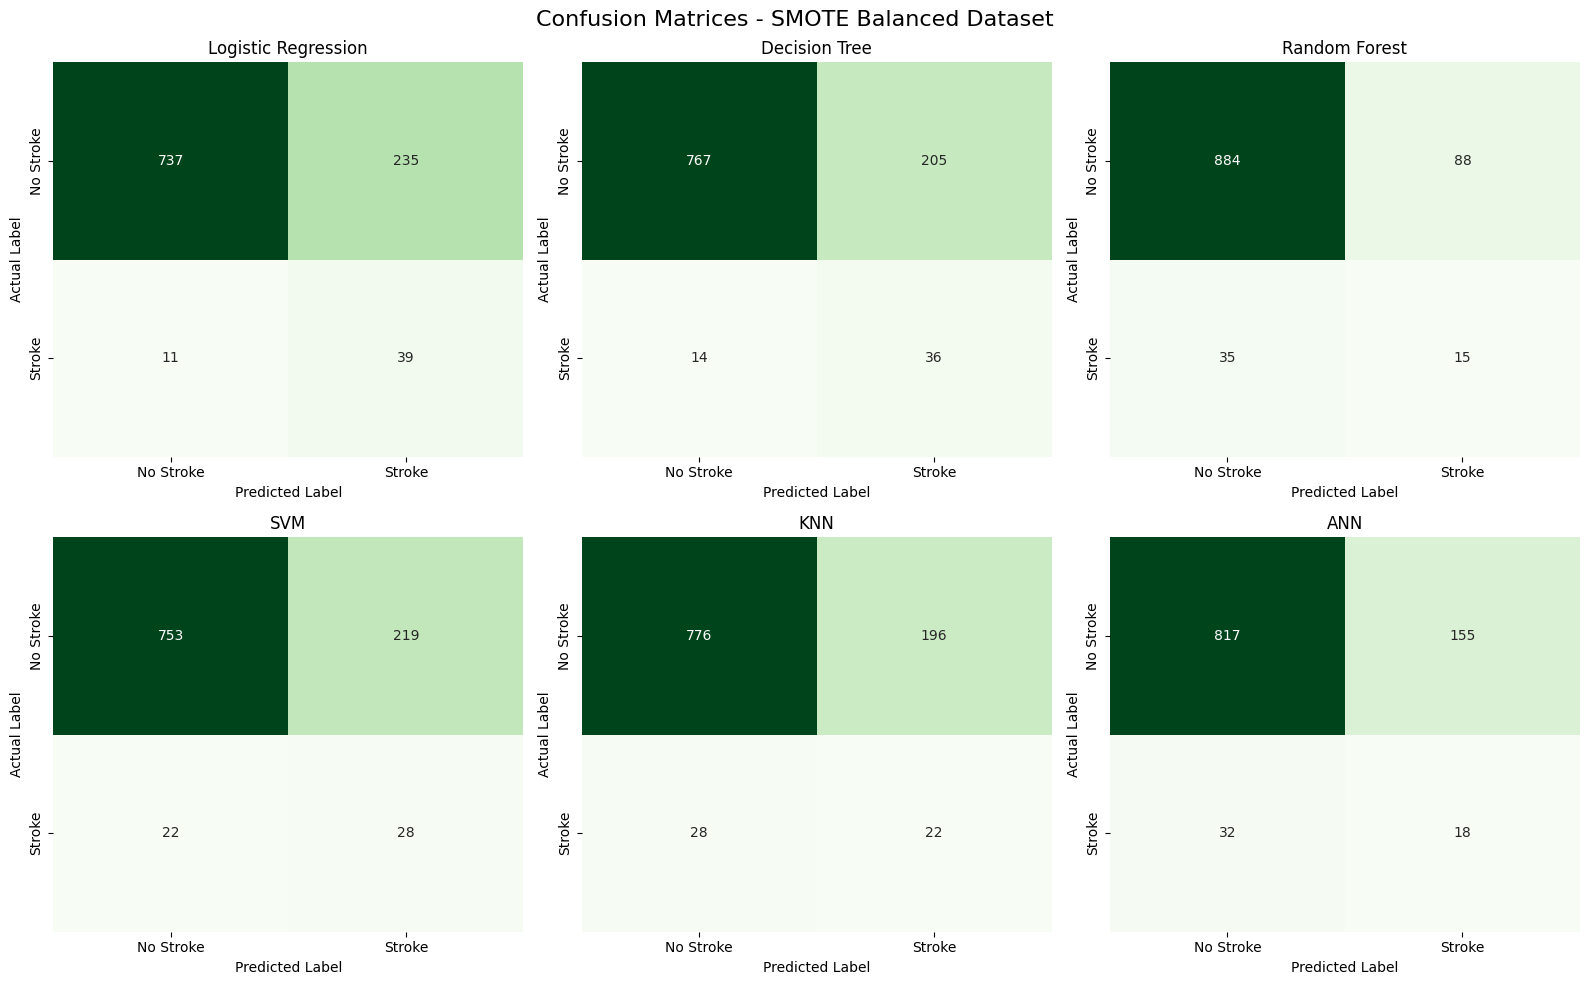

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, cm) in enumerate(smote_cm.items()):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        cbar=False,
        ax=axes[i],
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices - SMOTE Balanced Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

CONFUSION MATRIX COMPARISON


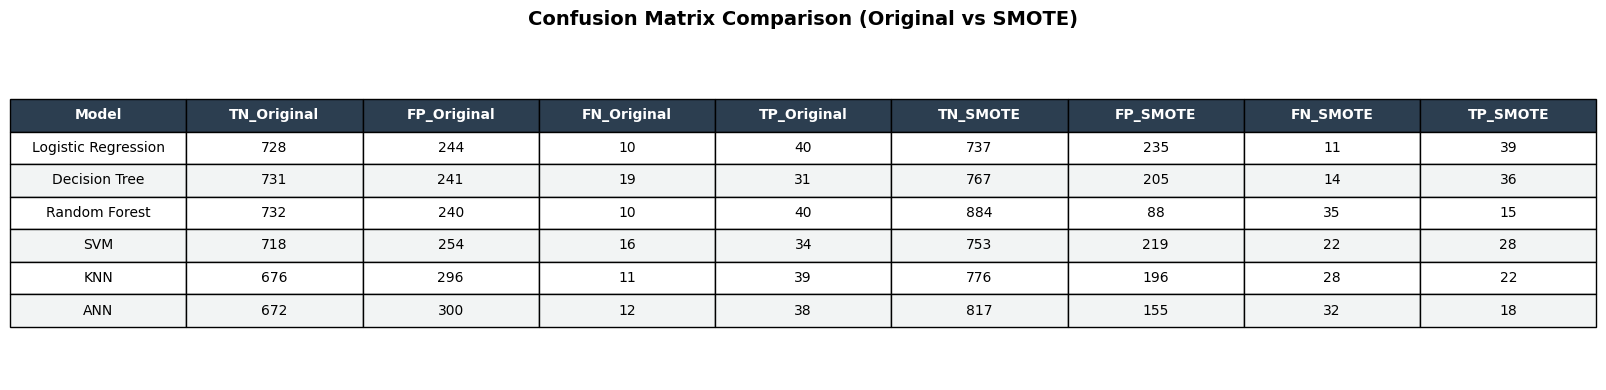

Table successfully rendered and saved as 'confusion_matrix_comparison.png'!


In [51]:
cm_comparison = []

for name in original_cm:

    cm_original = original_cm[name]
    cm_smote = smote_cm[name]

    tn_original, fp_original, fn_original, tp_original = (
        cm_original.ravel()
    )

    tn_smote, fp_smote, fn_smote, tp_smote = (
        cm_smote.ravel()
    )

    cm_comparison.append({

        "Model": name,

        "TN_Original": tn_original,
        "FP_Original": fp_original,
        "FN_Original": fn_original,
        "TP_Original": tp_original,

        "TN_SMOTE": tn_smote,
        "FP_SMOTE": fp_smote,
        "FN_SMOTE": fn_smote,
        "TP_SMOTE": tp_smote

    })

cm_comparison_df = pd.DataFrame(cm_comparison)

print("CONFUSION MATRIX COMPARISON")
print("=" * 80)

# Render and save the Confusion Matrix Comparison Table as an image
save_df_as_image(
    cm_comparison_df,
    title="Confusion Matrix Comparison (Original vs SMOTE)",
    filename="confusion_matrix_comparison.png",
    figsize=(16, 4)
)

CONFUSION MATRIX DELTA COMPARISON


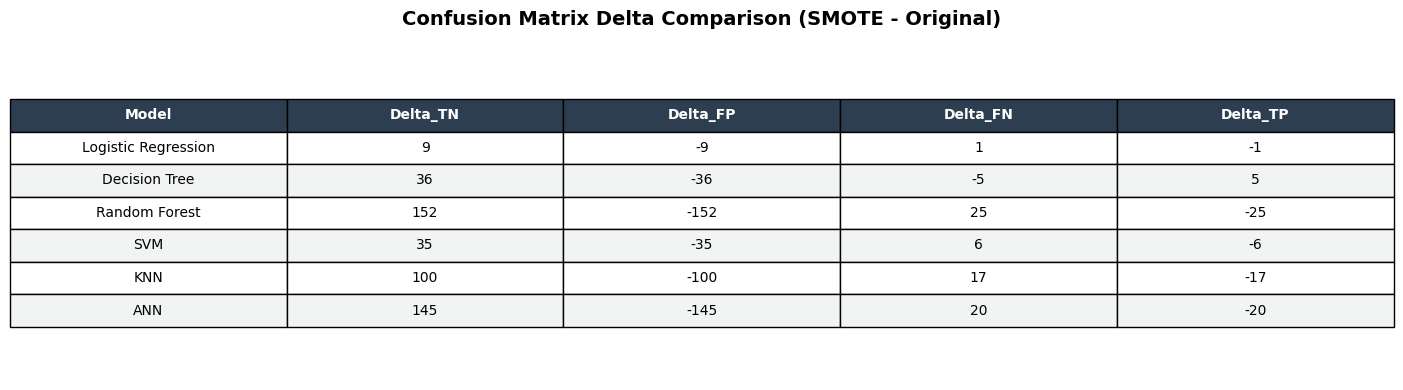

Table successfully rendered and saved as 'confusion_matrix_delta_comparison.png'!


In [52]:
cm_delta = pd.DataFrame()

cm_delta["Model"] = cm_comparison_df["Model"]

for col in ["TN", "FP", "FN", "TP"]:
    cm_delta["Delta_" + col] = (
        cm_comparison_df[col + "_SMOTE"] -
        cm_comparison_df[col + "_Original"]
    )

print("CONFUSION MATRIX DELTA COMPARISON")
print("=" * 80)

# Render and save the Confusion Matrix Delta Comparison Table as an image
save_df_as_image(
    cm_delta,
    title="Confusion Matrix Delta Comparison (SMOTE - Original)",
    filename="confusion_matrix_delta_comparison.png",
    figsize=(14, 4)
)

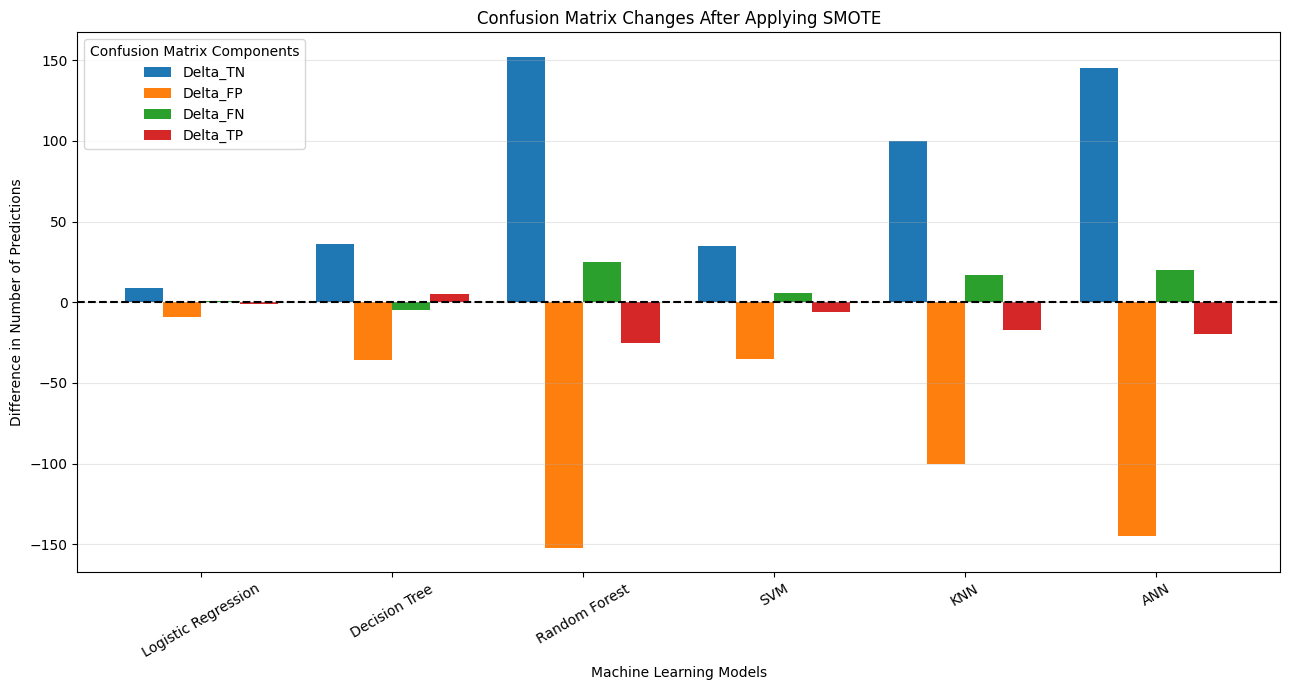

In [53]:
cm_delta_plot = cm_delta.set_index("Model")

cm_delta_plot.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--"
)

plt.title("Confusion Matrix Changes After Applying SMOTE")

plt.xlabel("Machine Learning Models")
plt.ylabel("Difference in Number of Predictions")

plt.xticks(rotation=30)

plt.legend(
    title="Confusion Matrix Components"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

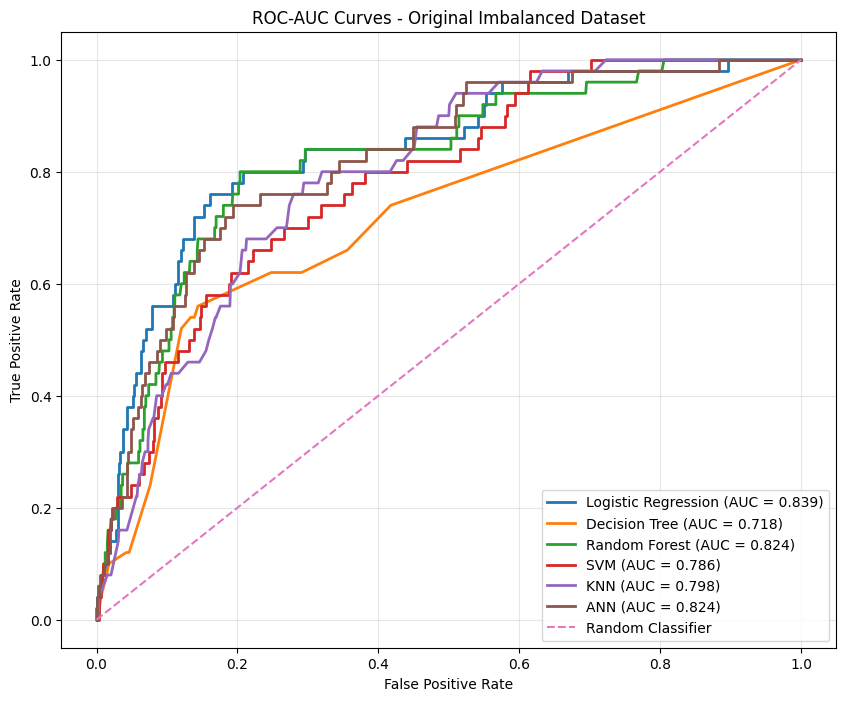

In [54]:
plt.figure(figsize=(10, 8))

for name, model in original_trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC-AUC Curves - Original Imbalanced Dataset")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

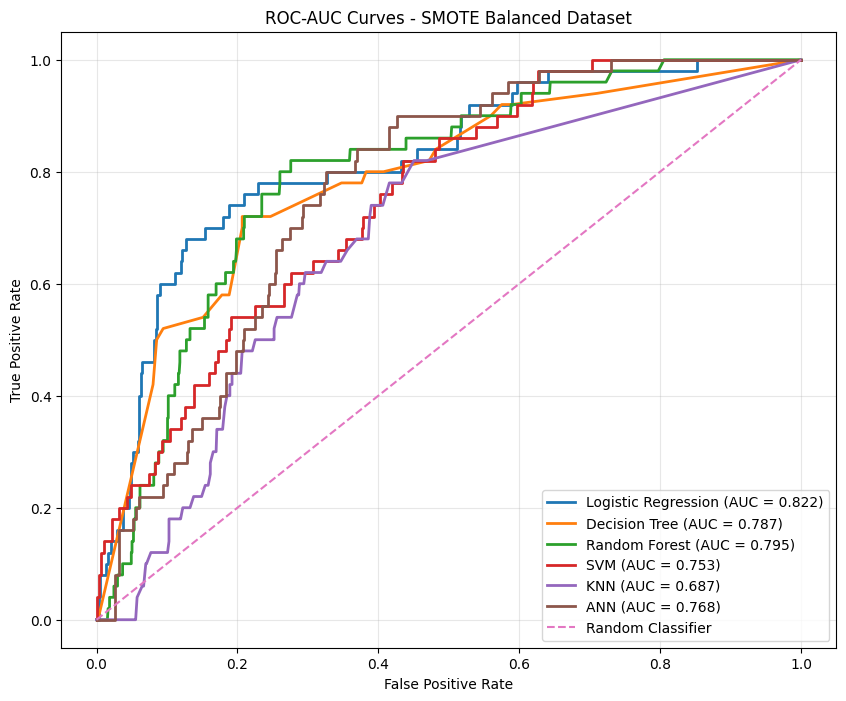

In [55]:
plt.figure(figsize=(10, 8))

for name, model in smote_trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC-AUC Curves - SMOTE Balanced Dataset")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

In [56]:
top_3 = smote_results.sort_values(
    by="F1-Score",
    ascending=False
).head(3).reset_index(drop=True)

top_3.insert(
    0,
    "Rank",
    [1, 2, 3]
)

print("TOP THREE MODELS AFTER SMOTE")

display(
    top_3.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "AUC-ROC": "{:.4f}"
    })
)

TOP THREE MODELS AFTER SMOTE


,Rank,Experiment,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,1,SMOTE Balanced,Decision Tree,0.7857,0.1494,0.7200,0.2474,0.7867
1,2,SMOTE Balanced,Logistic Regression,0.7593,0.1423,0.7800,0.2407,0.8219
2,3,SMOTE Balanced,Random Forest,0.8796,0.1456,0.3000,0.1961,0.7946


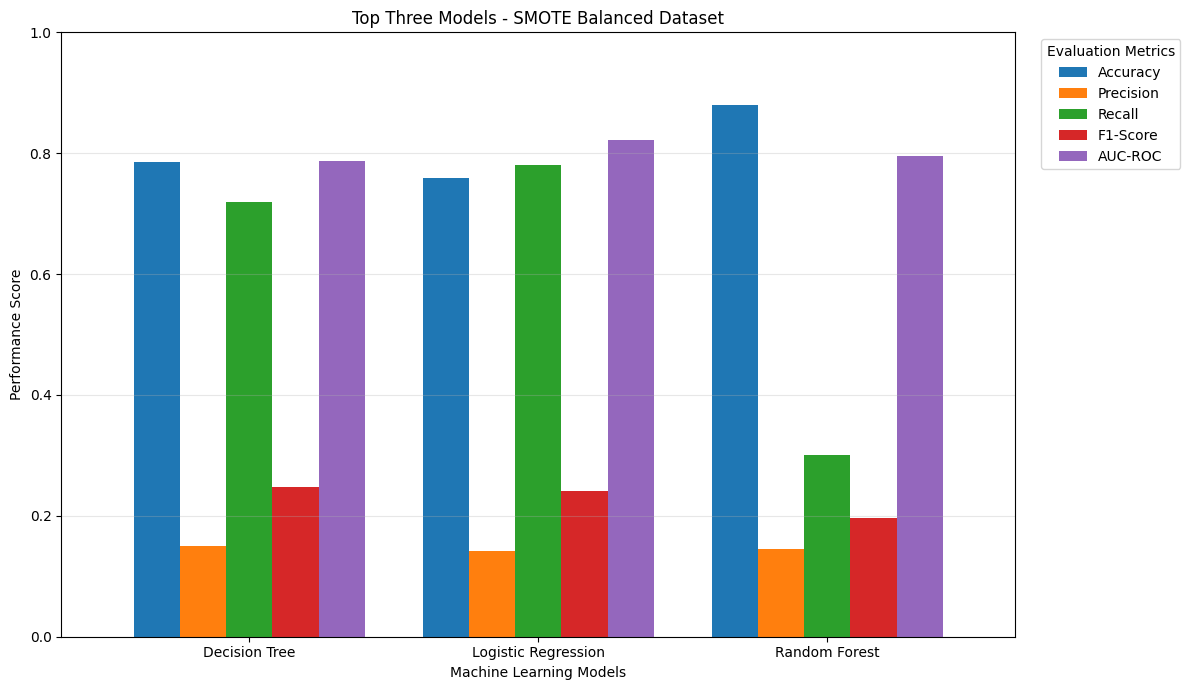

In [57]:
top3_metrics = top_3.set_index("Model")[metrics]

top3_metrics.plot(
    kind="bar",
    figsize=(12, 7),
    width=0.8
)

plt.title("Top Three Models - SMOTE Balanced Dataset")

plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


MODEL: Decision Tree
              precision    recall  f1-score   support

   No Stroke       0.98      0.79      0.88       972
      Stroke       0.15      0.72      0.25        50

    accuracy                           0.79      1022
   macro avg       0.57      0.75      0.56      1022
weighted avg       0.94      0.79      0.84      1022



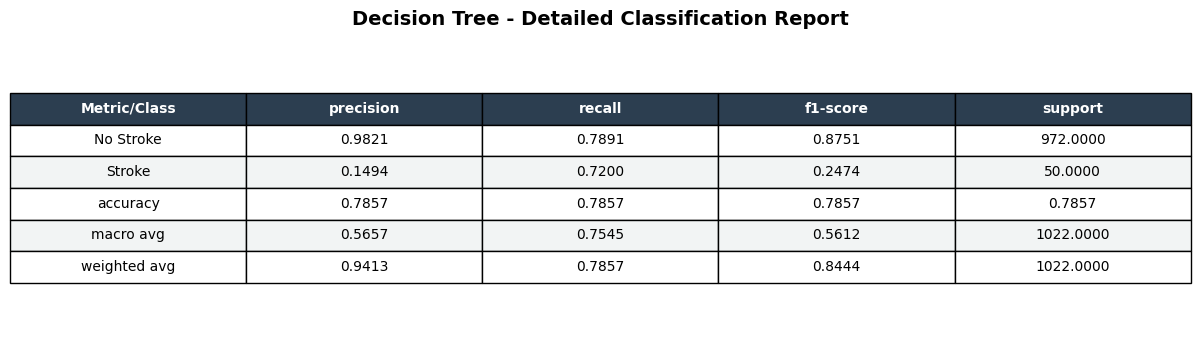

Table successfully rendered and saved as 'decision_tree_classification_report.png'!

MODEL: Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.99      0.76      0.86       972
      Stroke       0.14      0.78      0.24        50

    accuracy                           0.76      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.94      0.76      0.83      1022



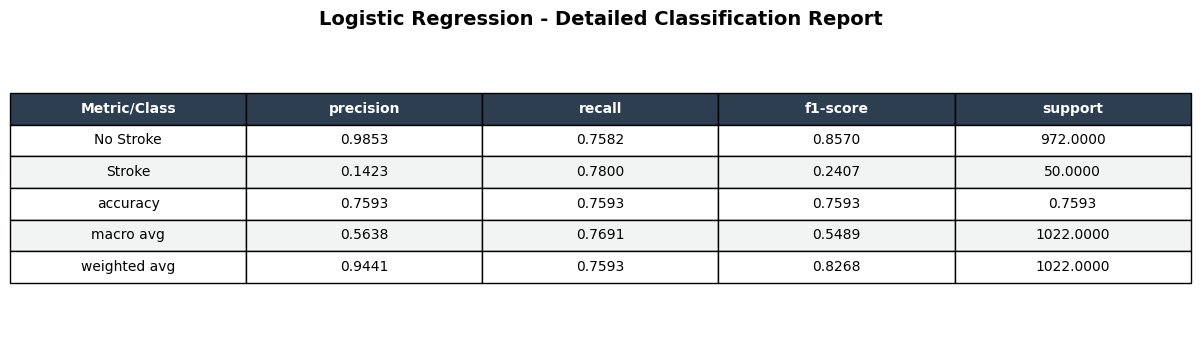

Table successfully rendered and saved as 'logistic_regression_classification_report.png'!

MODEL: Random Forest
              precision    recall  f1-score   support

   No Stroke       0.96      0.91      0.93       972
      Stroke       0.15      0.30      0.20        50

    accuracy                           0.88      1022
   macro avg       0.55      0.60      0.57      1022
weighted avg       0.92      0.88      0.90      1022



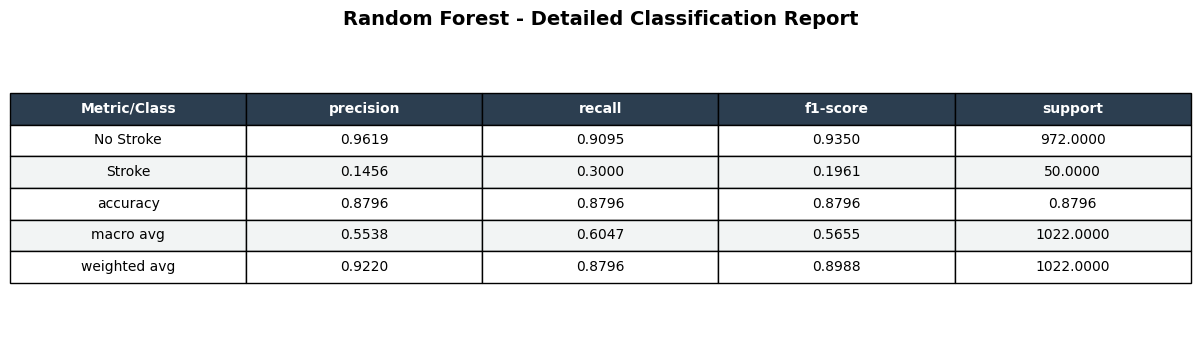

Table successfully rendered and saved as 'random_forest_classification_report.png'!


In [58]:
for name in top_3["Model"]:
    model = smote_trained_models[name]
    y_pred = model.predict(X_test)

    print("\n" + "=" * 65)
    print("MODEL:", name)
    print("=" * 65)

    # Generate classification report as text
    report_str = classification_report(
        y_test,
        y_pred,
        target_names=["No Stroke", "Stroke"],
        zero_division=0
    )
    print(report_str)

    # Generate classification report as dict to convert to DataFrame
    report_dict = classification_report(
        y_test,
        y_pred,
        target_names=["No Stroke", "Stroke"],
        zero_division=0,
        output_dict=True
    )

    # Structure the dictionary as an organized DataFrame
    report_df = pd.DataFrame(report_dict).transpose().reset_index()
    report_df.rename(columns={"index": "Metric/Class"}, inplace=True)

    # Render and save each report as a picture
    save_df_as_image(
        report_df,
        title=f"{name} - Detailed Classification Report",
        filename=f"{name.lower().replace(' ', '_')}_classification_report.png",
        figsize=(12, 3.5)
    )